In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np
import cv2 as cv
from google.colab.patches import cv2_imshow

Mengubah tingkat kecerahan citra
--------------------------------
Masukkan nilai kecerahan: 30


/tmp/ipykernel_11866/1868447545.py:14: RuntimeWarning: overflow encountered in scalar add
  brightness_image[y,x,c] = np.clip(original[y,x,c] + brightness, 0, 255)


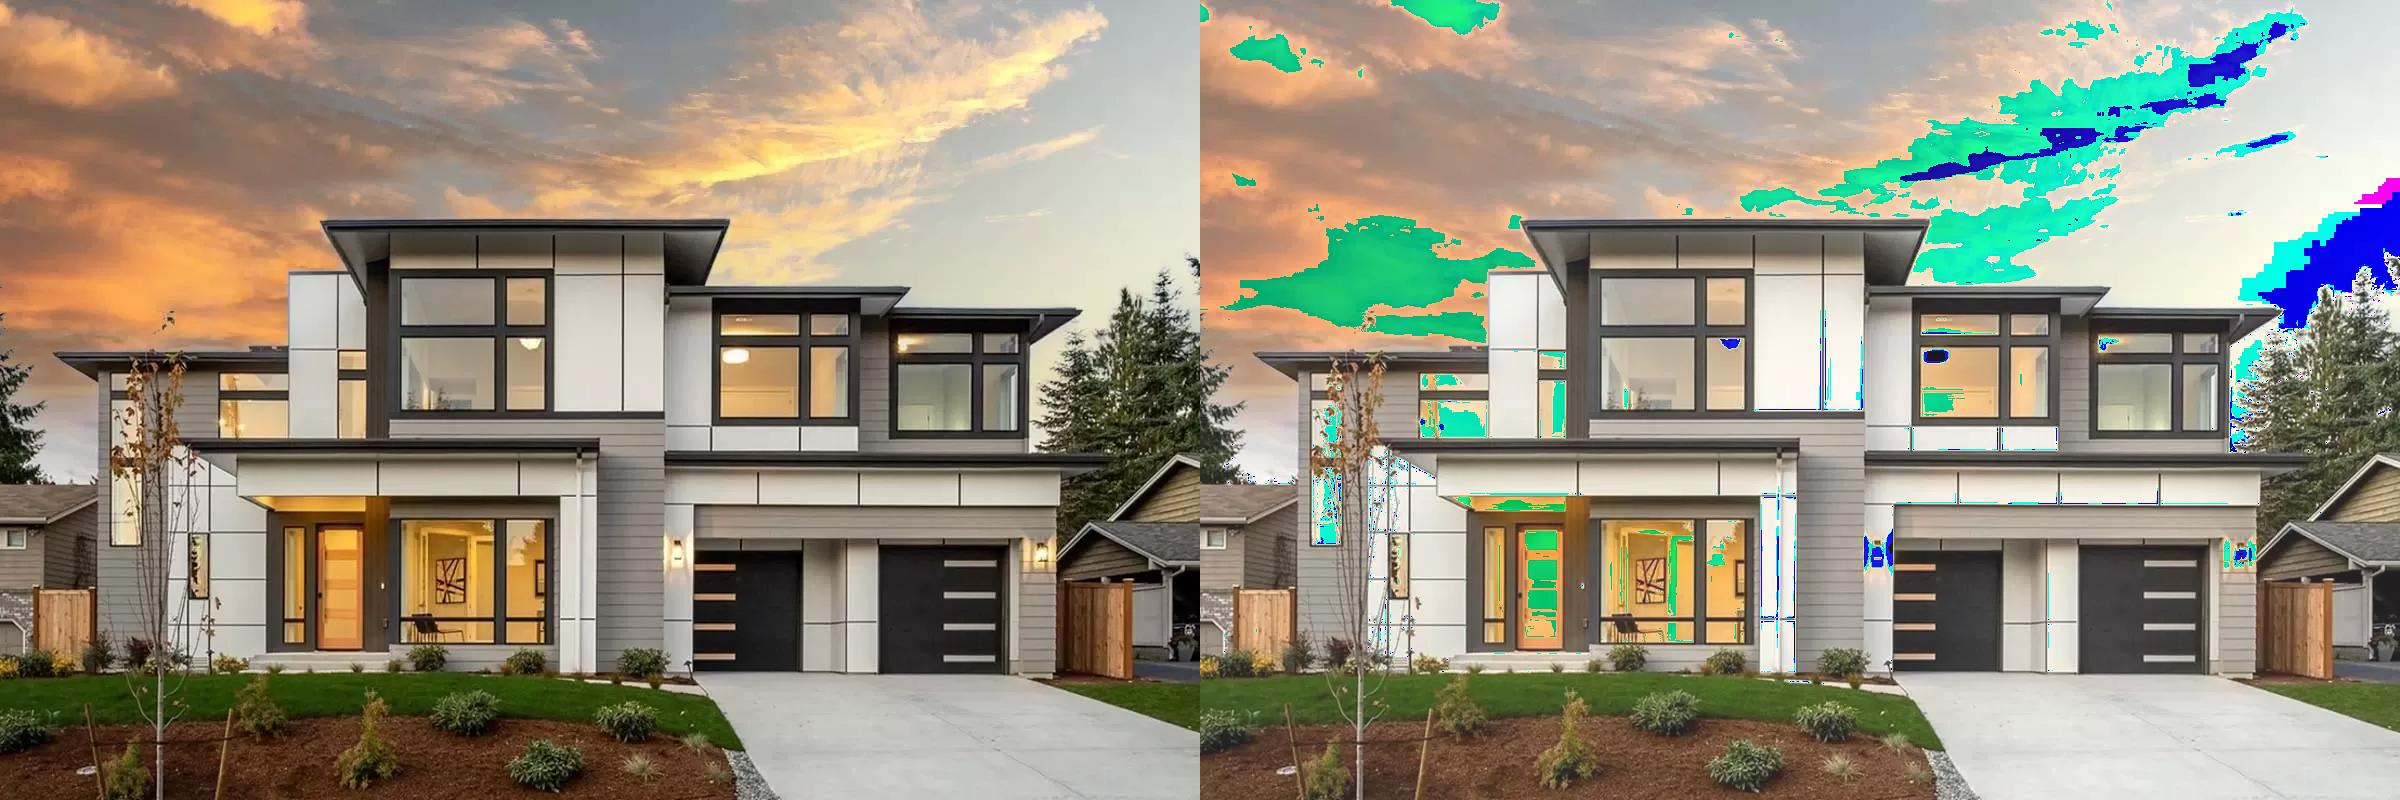

In [4]:
print('Mengubah tingkat kecerahan citra')
print('--------------------------------')
try:
  brightness = int(input('Masukkan nilai kecerahan: '))
except ValueError:
  print('Error, not a number')

original = cv.imread('/content/drive/MyDrive/PCVK/modern house.jpg')
brightness_image = np.zeros(original.shape, original.dtype)

for y in range(original.shape[0]):
  for x in range(original.shape[1]):
    for c in range(original.shape[2]):
      brightness_image[y,x,c] = np.clip(original[y,x,c] + brightness, 0, 255)

final_frame = cv.hconcat((original, brightness_image))
cv2_imshow(final_frame)

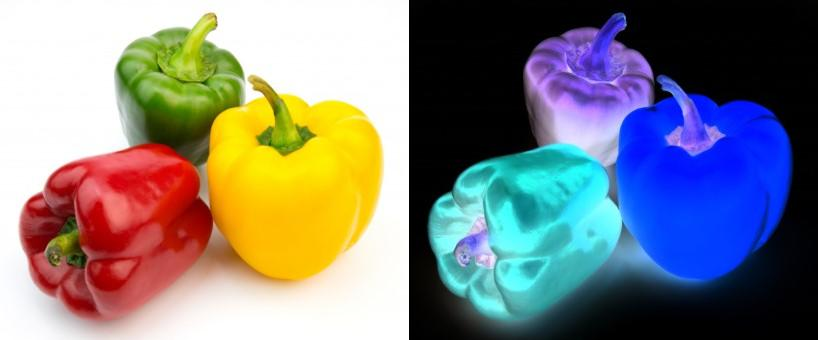

In [5]:
original  = cv.imread('/content/drive/MyDrive/PCVK/peppers.jpg')
orignal = 255 - original

final_frame = cv.hconcat((original, orignal))
cv2_imshow(final_frame)

2. Implementasikan transformasi contrast pada Google Colaboratory menggunakan formula yang terdapat pada bagian Ulasan Teori untuk kontras, sehingga menghasilkan keluaran seperti berikut:

Mengubah kontras dan tingkat kecerahan citra
---------------------------------------------
Masukkan tingkat kecerahan : 10
Masukkan kontras : 1.5


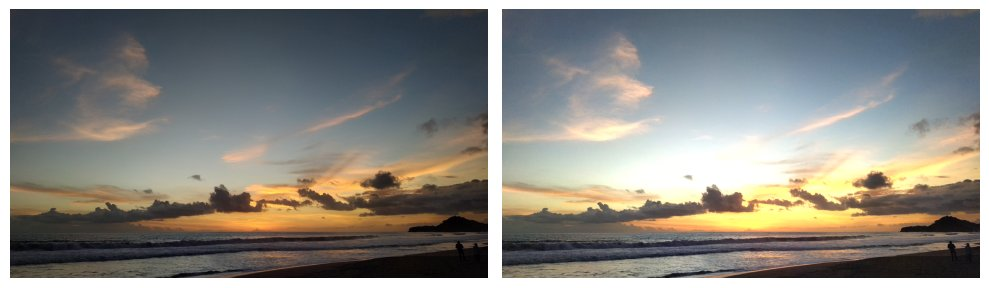

In [6]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

def truncate(val):
    if val > 255:
        return 255
    elif val < 0:
        return 0
    return int(val)

img = cv.imread("/content/drive/MyDrive/PCVK/sunset.jpg")
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

print("Mengubah kontras dan tingkat kecerahan citra")
print("---------------------------------------------")
kecerahan = float(input("Masukkan tingkat kecerahan : "))  # contoh: 10
kontras = float(input("Masukkan kontras : "))  # contoh: 1.5

tinggi, lebar, kanal = img_rgb.shape

img_hasil = np.zeros((tinggi, lebar, kanal), dtype=np.uint8)

for y in range(tinggi):
    for x in range(lebar):
        for c in range(kanal):
            nilai_baru = (kontras * img_rgb[y, x, c]) + kecerahan
            img_hasil[y, x, c] = truncate(nilai_baru)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_hasil)
plt.axis("off")

plt.tight_layout()
plt.show()

3. Implementasikan transformasi logarithmic brightness pada Google Colaboratory menggunakan formula yang terdapat pada bagian Ulasan Teori untuk transformasi log, sehingga menghasilkan keluaran seperti berikut:

Mengubah tingkat kecerahan citra dengan Transformasi Log
--------------------------------------------------------
Masukkan nilai kecerahan:50


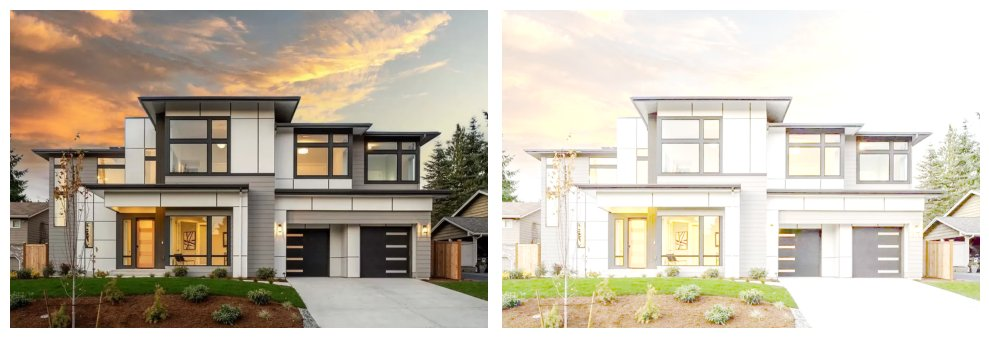

In [8]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

print('Mengubah tingkat kecerahan citra dengan Transformasi Log')
print('--------------------------------------------------------')

try:
  c = float(input('Masukkan nilai kecerahan:' ))
except ValueError:
  print('Error, not a number')

img = cv.imread('/content/drive/MyDrive/PCVK/houses.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

img_float = img.astype(np.float32)
img_log = c * np.log1p(img_float)

img_hasil = np.clip(img_log, 0, 255).astype(np.uint8)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_hasil, cmap="gray")
plt.axis("off")
plt.tight_layout()
plt.show()

4. Implementasikan transformasi grayscale menggunakan metode averaging, lightness, dan luminance pada Google Colaboratory menggunakan formula yang terdapat pada bagian Ulasan Teori, sehingga menghasilkan keluaran seperti berikut:

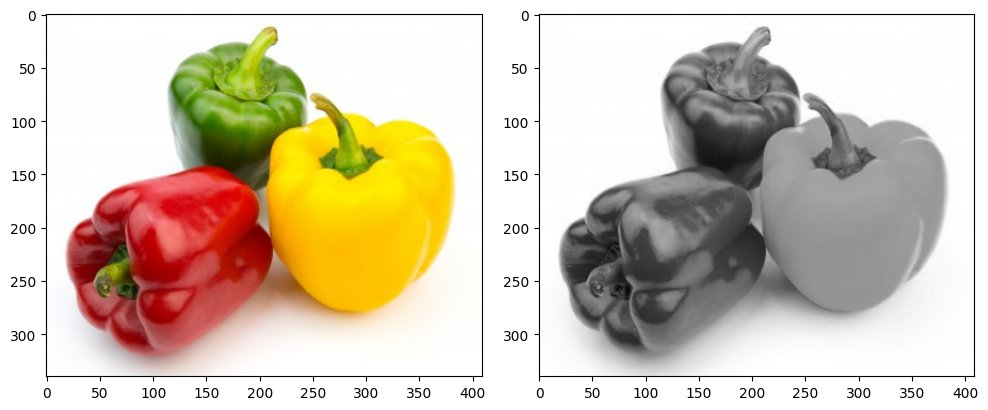

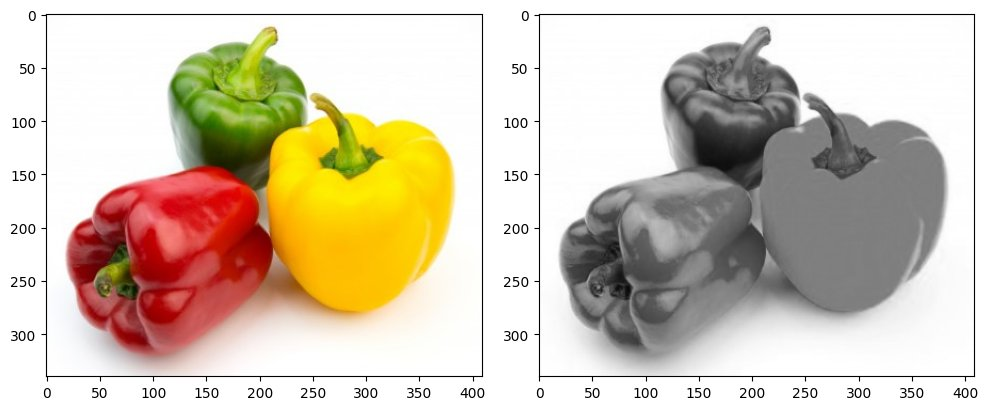

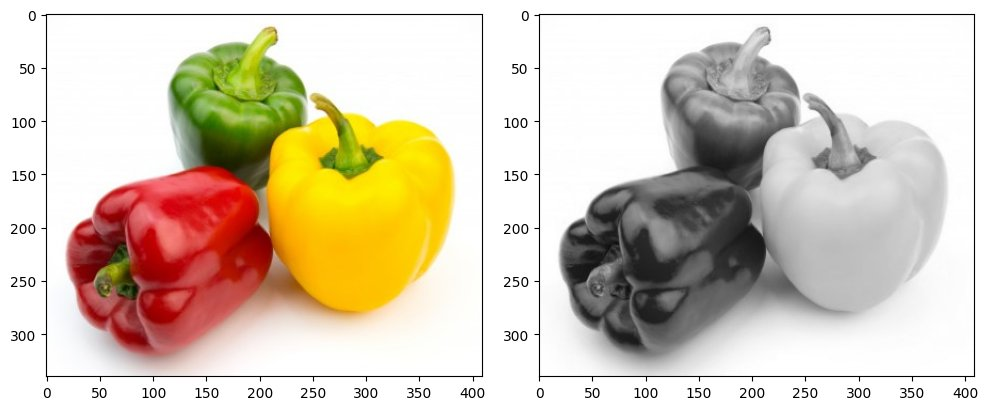

In [9]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

img = cv.imread("/content/drive/MyDrive/PCVK/peppers.jpg")
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

R = img_rgb[:, :, 0].astype(np.float32)
G = img_rgb[:, :, 1].astype(np.float32)
B = img_rgb[:, :, 2].astype(np.float32)

# a. Averaging --> Formula: (R + G + B) / 3

gray_avg = ((R + G + B) / 3).astype(np.uint8)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)

plt.subplot(1, 2, 2)
plt.imshow(gray_avg, cmap="gray", vmin=0, vmax=255)

plt.tight_layout()
plt.show()

# b. Lightness --> Formula: (max[R, G, B] + min[R, G, B]) / 2
max_rgb = np.maximum(np.maximum(R, G), B)
min_rgb = np.minimum(np.minimum(R, G), B)
gray_lightness = ((max_rgb + min_rgb) / 2).astype(np.uint8)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)

plt.subplot(1, 2, 2)
plt.imshow(gray_lightness, cmap="gray", vmin=0, vmax=255)

plt.tight_layout()
plt.show()

# c. Luminance

gray_luminance = (0.21 * R + 0.72 * G + 0.07 * B).astype(np.uint8)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)

plt.subplot(1, 2, 2)
plt.imshow(gray_luminance, cmap="gray", vmin=0, vmax=255)

plt.tight_layout()
plt.show()

5. Tampilkanlah warna tertentu pada citra, dan ubah warna lain menjadi grayscale. Misal, tampilkan warna merah pada citra masukan dan ubah bagian lain yang tidak berwarna merah menjadi grayscale seperti pada contoh berikut:

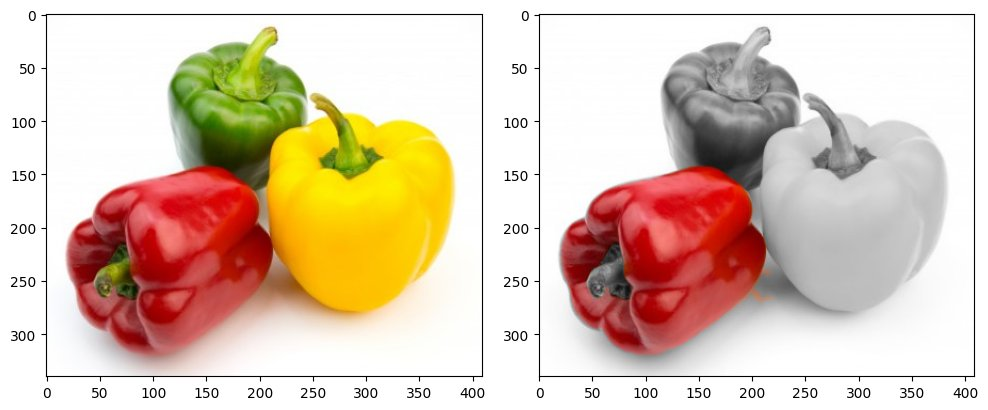

In [10]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

img = cv.imread("/content/drive/MyDrive/PCVK/peppers.jpg")
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

img_hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)

lower_red1 = np.array([0, 100, 50])
upper_red1 = np.array([10, 255, 255])

lower_red2 = np.array([170, 100, 50])
upper_red2 = np.array([180, 255, 255])

mask1 = cv.inRange(img_hsv, lower_red1, upper_red1)
mask2 = cv.inRange(img_hsv, lower_red2, upper_red2)
red_mask = cv.bitwise_or(mask1, mask2)

gray = cv.cvtColor(img_rgb, cv.COLOR_RGB2GRAY)
gray_3ch = cv.cvtColor(gray, cv.COLOR_GRAY2RGB)

mask_3ch = red_mask == 255
img_hasil = np.where(mask_3ch[:, :, None], img_rgb, gray_3ch)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)

plt.subplot(1, 2, 2)
plt.imshow(img_hasil)

plt.tight_layout()
plt.show()

6. Buat Gamma Correction sesuai dengan petunjuk berikut Percobaan ini akan meminta anda membuat Gamma Correction. Pada percobaan ini, nilai Gamma akan diset dengan meminta masukan dari pengguna. Berikut adalah kode untuk meminta masukan nilai dari pengguna. Lanjutkan kode tersebut dengan membuat image dengan gamma correction sesuai rumus yang telah diberikan.

 Gamma Correction pada citra 
----------------------------------
Masukkan nilai Gamma: 0.5


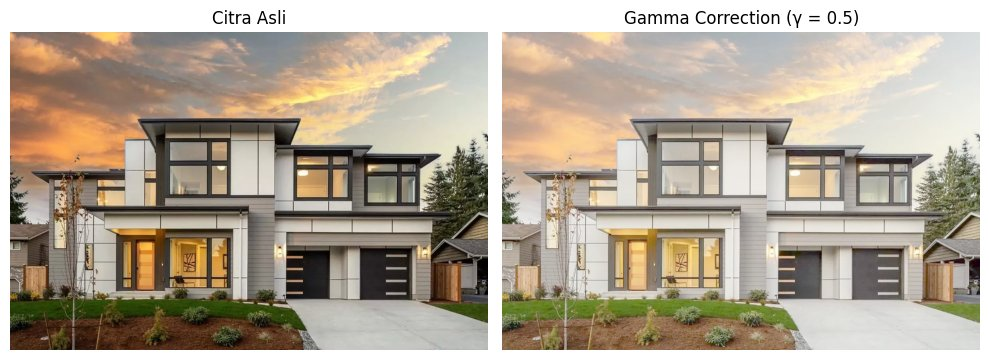

In [11]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np


print(' Gamma Correction pada citra ')
print('----------------------------------')
try:
  gamma = float(input('Masukkan nilai Gamma: '))
except ValueError:
  print('Error, not a number')

img = cv.imread("/content/drive/MyDrive/PCVK/houses.jpg")
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

img_norm = img_rgb.astype(np.float32) / 255.0
gamma_corrected = 255.0 * (img_norm**gamma)

img_hasil = np.clip(gamma_corrected, 0, 255).astype(np.uint8)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_hasil)
plt.title(f"Gamma Correction (γ = {gamma})")
plt.axis("off")

plt.tight_layout()
plt.show()

7. Buat Simulasi Image Depth Percobaan ini digunakan sebagai simulasi dari proses kuantisasi citra. Pada kuantisasi citra, pixel dapat direpresentasikan dengan n-bit kedalaman (default menggunakan 8-bit). Pada pixel 8-bit, warna yang memungkinkan adalah 256 warna, dari 0 (0000 0000) hingga 255(1111 1111). Pada pixel 7-bit, warna yang memungkinkan adalah 128 warna, dari 0 (000 0000) hingga 127 (111 1111). Kemungkinan warna didapat dari pangkat 2 jumlah bit. Jika 7bit, maka jumlah warnanya adalah 27 = 128, dst.

Masukkan bit depth tujuan (1-8): 3
Bit depth awal  : 8 bit
Bit depth tujuan: 3 bit
Jumlah level    : 8


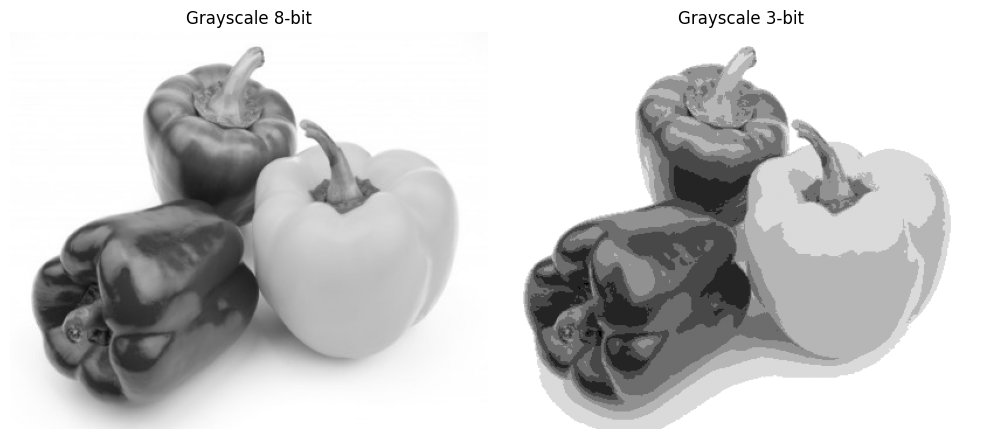

In [12]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

bit_depth = int(input("Masukkan bit depth tujuan (1-8): "))

jumlah_level = pow(2, bit_depth)
print(f"Bit depth awal  : 8 bit")
print(f"Bit depth tujuan: {bit_depth} bit")
print(f"Jumlah level    : {jumlah_level}")

level = 255 / (pow(2, bit_depth) - 1)


original = cv.imread("/content/drive/MyDrive/PCVK/peppers.jpg",cv.IMREAD_GRAYSCALE,)

depth_image = np.round(original / level) * level
depth_image = np.clip(depth_image, 0, 255).astype(np.uint8)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Grayscale 8-bit")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(depth_image, cmap="gray", vmin=0, vmax=255)
plt.title(f"Grayscale {bit_depth}-bit")
plt.axis("off")

plt.tight_layout()
plt.show()

8. Buat modul Average Denoising Buat modul average denoising sesuai dengan rumus yang telah diberikan pada sub bab sebelumnya.

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import cv2 as cv
import glob
import os

# ==========================================
# 1. MEMBACA CITRA ASLI
# ==========================================
path_asli = "/content/drive/MyDrive/PCVK/galaxy.jpg"

original = cv.imread(path_asli)

if original is None:
    raise FileNotFoundError("Citra asli galaxy.jpg tidak ditemukan!")

original_rgb = cv.cvtColor(original, cv.COLOR_BGR2RGB)


# ==========================================
# 2. MEMBACA CITRA NOISE
# ==========================================
path_noises = "/content/drive/MyDrive/PCVK/images/noises/*.jpg"

files = sorted(glob.glob(path_noises))

cv_img = []

for file in files:

    n = cv.imread(file)

    if n is not None:

        n_rgb = cv.cvtColor(n, cv.COLOR_BGR2RGB)

        if n_rgb.shape == original_rgb.shape:
            cv_img.append(n_rgb)
        else:
            print("Ukuran gambar berbeda:", os.path.basename(file))

print("Total citra bernoise yang dimuat:", len(cv_img))


# ==========================================
# 3. MENENTUKAN JUMLAH CITRA
# ==========================================
target_citra = [10, 20, 40, 80, 100]

# Hanya jumlah yang tersedia dan bisa diproses
jumlah_citra = [k for k in target_citra if k <= len(cv_img)]

if len(cv_img) == 0:
    print("Tidak ada gambar noise yang berhasil dimuat!")
else:
    print("Jumlah citra yang akan digunakan:", jumlah_citra)


# ==========================================
# 4. PROSES AVERAGE DENOISING
# ==========================================
hasil_denoised = []
nilai_psnr = []

for k in jumlah_citra:

    # Mengambil k citra noise
    subset = np.stack(cv_img[:k]).astype(np.float32)

    # Menghitung rata-rata citra
    avg_img = np.mean(subset, axis=0)

    # Mengubah kembali ke uint8
    avg_img = np.clip(avg_img, 0, 255).astype(np.uint8)

    # Memastikan format array
    original_rgb = np.ascontiguousarray(original_rgb, dtype=np.uint8)
    avg_img = np.ascontiguousarray(avg_img, dtype=np.uint8)

    # Menghitung PSNR
    psnr = cv.PSNR(original_rgb, avg_img)

    # Menyimpan hasil
    hasil_denoised.append(avg_img)
    nilai_psnr.append(psnr)

    print(f"Jumlah Citra: {k:<3} | Nilai PSNR: {psnr:.2f} dB")


# ==========================================
# 5. VISUALISASI HASIL
# ==========================================
if len(hasil_denoised) > 0:

    plt.figure(figsize=(18, 4))

    for i, k in enumerate(jumlah_citra):

        plt.subplot(1, len(jumlah_citra), i + 1)

        plt.imshow(hasil_denoised[i])

        plt.title(f"K = {k}\nPSNR: {nilai_psnr[i]:.2f} dB")

        plt.axis("off")

    plt.tight_layout()
    plt.show()

Total citra bernoise yang dimuat: 0
Tidak ada gambar noise yang berhasil dimuat!


9. Buat image masking Buat image masking untuk image berikut. Image kiri adalah image asli (images/couple.tiff), sedangkan image paling kanan adalah hasilnya:

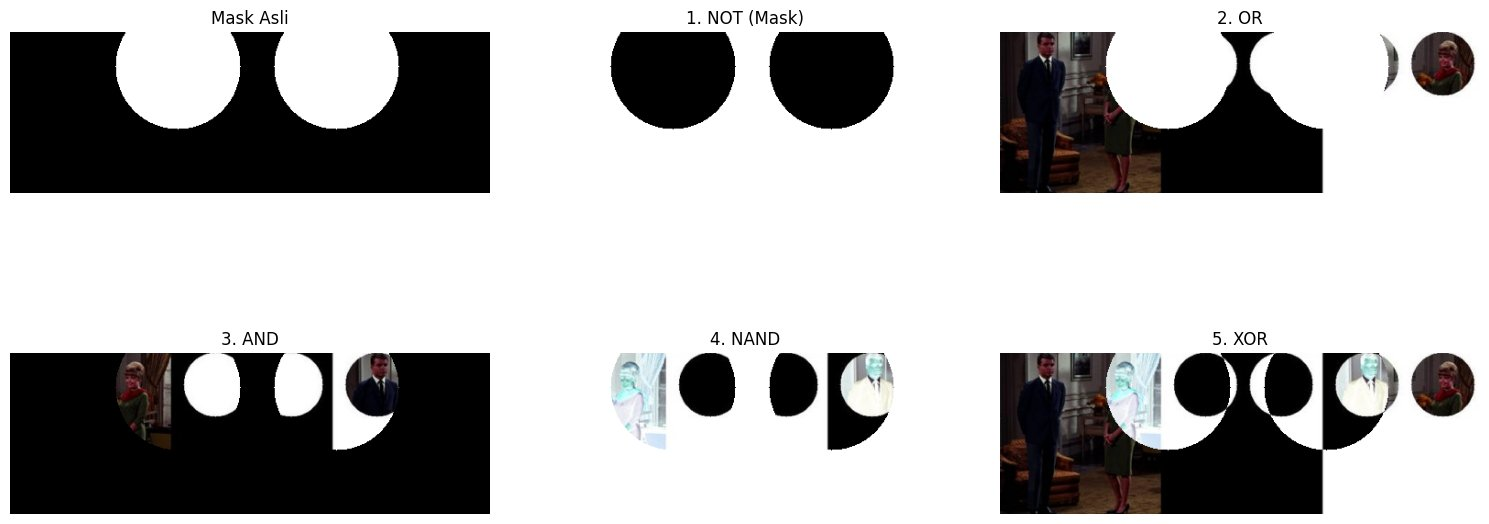

In [28]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

img = cv.imread("/content/drive/MyDrive/PCVK/couple.tiff")

img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
h, w, _ = img_rgb.shape

mask = np.zeros((h, w), dtype=np.uint8)

cv.circle(mask, (int(w * 0.35), int(h * 0.22)), int(w * 0.13), 255, -1)
cv.circle(mask, (int(w * 0.68), int(h * 0.22)), int(w * 0.13), 255, -1)

mask_3ch = cv.merge([mask, mask, mask])

out_not_mask = cv.bitwise_not(mask_3ch)
out_not_img = cv.bitwise_not(img_rgb)

out_or = cv.bitwise_or(img_rgb, mask_3ch)

out_and = cv.bitwise_and(img_rgb, mask_3ch)

out_nand = cv.bitwise_not(out_and)

out_xor = cv.bitwise_xor(img_rgb, mask_3ch)

opsi_tampil = [
    ("Mask Asli", mask),
    ("1. NOT (Mask)", out_not_mask),
    ("2. OR", out_or),
    ("3. AND", out_and),
    ("4. NAND", out_nand),
    ("5. XOR", out_xor),
]

plt.figure(figsize=(15, 8))
for i, (judul, hasil) in enumerate(opsi_tampil):
    plt.subplot(2, 3, i + 1)
    if len(hasil.shape) == 2:
        plt.imshow(hasil, cmap="gray")
    else:
        plt.imshow(hasil)
    plt.title(judul)
    plt.axis("off")

plt.tight_layout()
plt.show()

10. Foto Malam Hari Carilah foto malam hari yang gelap. Namun, beberapa bagian gambar memiliki detail yang sebenarnya cukup baik. Pilih salah satu metode berikut dan implementasikan pada foto tersebut (Linear Brightness, Contrast, Logarithmic Brightness, Gamma Correction). Sebutkan alasan dan resiko metode yang Anda gunakan.

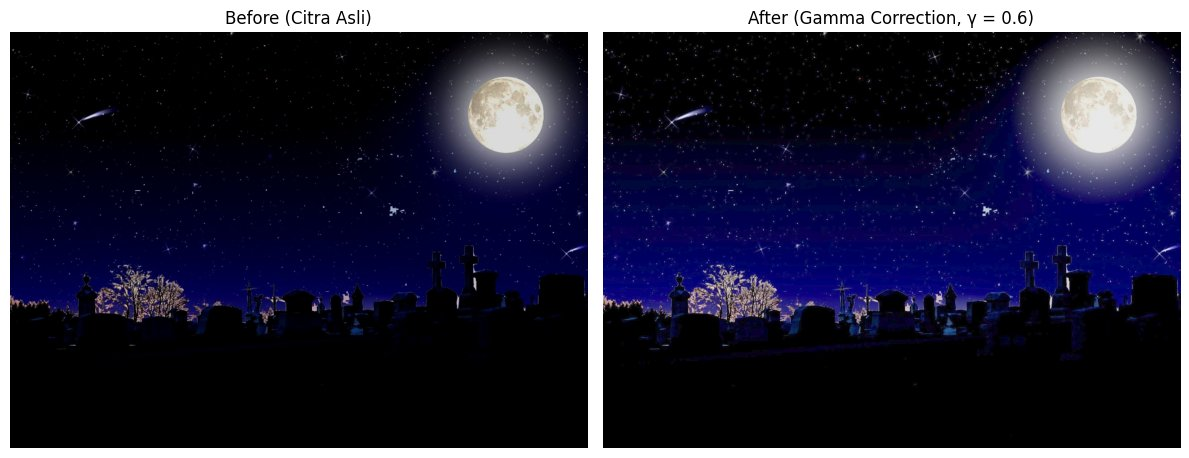

In [29]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

img = cv.imread("/content/drive/MyDrive/PCVK/malam.jpg" )
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# 2. Implementasi Gamma Correction
# Nilai gamma < 1 (contoh: 0.55 - 0.65) untuk mengangkat detail gelap tanpa merusak area terang
gamma = 0.6

# Normalisasi rentang ke [0.0, 1.0], lakukan perpangkatan, lalu kalikan kembali 255
img_norm = img_rgb.astype(np.float32) / 255.0
gamma_corrected = 255.0 * (img_norm**gamma)
img_hasil = np.clip(gamma_corrected, 0, 255).astype(np.uint8)

# 3. Tampilkan perbandingan Sebelum (Before) dan Sesudah (After)
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Before (Citra Asli)", fontsize=12)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_hasil)
plt.title(f"After (Gamma Correction, γ = {gamma})", fontsize=12)
plt.axis("off")

plt.tight_layout()
plt.show()

11. Perbaiki kualitas pada citra tersebut dengan metode operasi dasar citra apapun. Diperbolehkan menggunakan lebih dari 1 metode. Kemudian jelaskan: • Metode yang dipilih • Alasan pemilihan • Menentukan parameter terbaik • Menghasilkan citra dengan menunjukkan before-after.

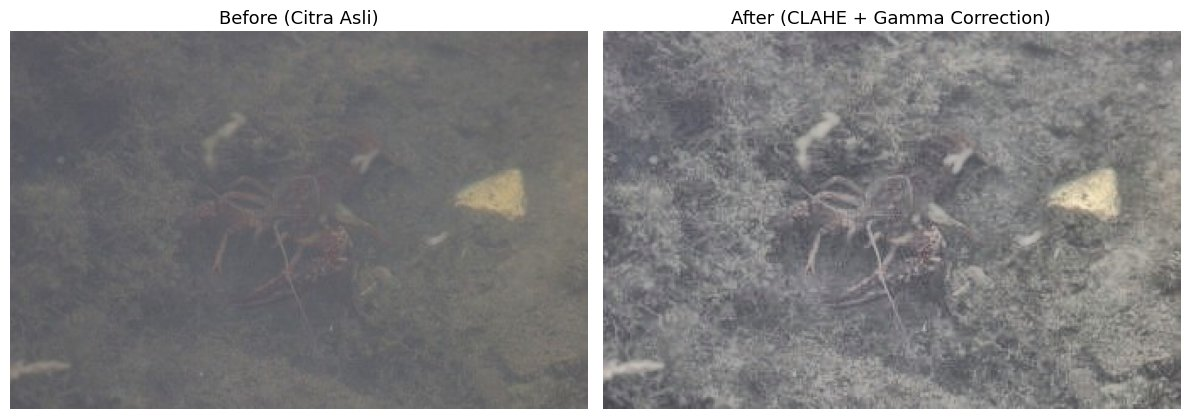

In [30]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

path_gambar = "/content/drive/MyDrive/PCVK/crayfish.jpg"
img = cv.imread(path_gambar)

img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

img_lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
l_channel, a_channel, b_channel = cv.split(img_lab)

clahe = cv.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
cl = clahe.apply(l_channel)

merged_lab = cv.merge((cl, a_channel, b_channel))
img_clahe = cv.cvtColor(merged_lab, cv.COLOR_LAB2RGB)

gamma = 0.85
img_norm = img_clahe.astype(np.float32) / 255.0
img_hasil = np.clip(255.0 * (img_norm**gamma), 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Before (Citra Asli)", fontsize=13)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_hasil)
plt.title("After (CLAHE + Gamma Correction)", fontsize=13)
plt.axis("off")

plt.tight_layout()
plt.show()